<a href="https://colab.research.google.com/github/Mukundan-T/seqADAGE/blob/main/Py/muk_uADAGE/L1OnlyEcoliModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# L1-Only Regularized E. coli Models

### By: Mukundan Thanigaivelan

### October 11, 2026

In this notebook, we will be training E. coli models with the standard ADAGE loss function (mean squared error) in addition to a **L1 regularizer** as experimental models.

## Georgia's comments

- Consider same encoding and decoding activation functions
- Consider reconstruction error as a technical model metric:
  + [Georgia's Article](https://medium.com/@amnahhmohammed/autoencoders-and-testing-their-potential-in-anomaly-detection-09135140fd56)
  + The article, but without the 'faulty' data part, just like at the end with:

```
reconstructions_train = model.predict(train_transformed)
reconstruction_errors_normal_train = np.mean(np.abs(train_transformed - reconstructions_train), axis=1)

reconstructions_test = model.predict(test_transformed)
reconstruction_errors_normal_test = np.mean(np.abs(test_transformed - reconstructions_test), axis=1)
```

## 0. Connect to GitHub

In [1]:
!git clone https://github.com/Mukundan-T/seqADAGE.git

Cloning into 'seqADAGE'...
remote: Enumerating objects: 990, done.
remote: Counting objects: 100% (212/212), done.
remote: Compressing objects: 100% (141/141), done.
remote: Total 990 (delta 163), reused 77 (delta 71), pack-reused 778 (from 2)
Receiving objects: 100% (990/990), 59.58 MiB | 32.67 MiB/s, done.
Resolving deltas: 100% (582/582), done.


In [2]:
%cd seqADAGE/Py/muk_uADAGE

/content/seqADAGE/Py/muk_uADAGE


In [3]:
!pip install -qq tensorflow keras statsmodels seaborn keras_tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 7.0 MB/s eta 0:00:00


## 1. Loading classes & modules

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

In [6]:
# ADAGE
from adage import Adage as ad, SeqAdage, LinkedAE

# Data Analysis
import pandas as pd
import numpy as np
import keras

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Miscellaneous
import zipfile
import time
import json
import tensorflow as tf
from types import SimpleNamespace

In [7]:
# check CPU and GPU available in runtime
print("Num CPUs Available: ", len(tf.config.list_physical_devices('CPU')))
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print(tf.test.is_built_with_cuda())

Num CPUs Available:  1
Num GPUs Available:  1
True


## 2. L1 E. coli ADAGE

Hyperparameter search results:

* Units: 90
* Dropout: 0
* Activation 1: Sigmoid
* Activation 2: Sigmoid
* Shuffle: True
* Initialization: glorot_uniform
* kl1: 0.045
* kl2: 0
* lr: 0.001
* bs: 55
* mm: 0.8

### 2a. Find and save optimal model hyperparameters

In [8]:
# Load filtered and re-normalized data
filename = '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk.csv'

filtered_df = pd.read_csv(filename, index_col = 0)
filtered_df.shape

(3608, 10233)

In [ ]:
# Find optimal hyperparameter values
model_trainer = SeqAdage.SeqAdage(filename)
best_hps, tuner = model_trainer.tune_model(
  seed = 42,
  k2 = [0, 0, 0.1],
  d = [0, 0, 0.1]
)

Trial 90 Complete [00h 00m 46s]
val_loss: 19.249500274658203

Best val_loss So Far: 0.011146491393446922
Total elapsed time: 00h 25m 03s
Results summary
Results in /content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk_42
Showing 10 best trials
Objective(name="val_loss", direction="min")

Trial 0050 summary
Hyperparameters:
units: 40
dropout: 0.0
act1: celu
shuffle: True
init: glorot_normal
kl1: 0.0
kl2: 0.0
lr: 0.07100000000000001
bs: 55
mm: 0.2
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0046
Score: 0.011146491393446922

Trial 0046 summary
Hyperparameters:
units: 40
dropout: 0.0
act1: celu
shuffle: True
init: glorot_normal
kl1: 0.0
kl2: 0.0
lr: 0.07100000000000001
bs: 55
mm: 0.2
tuner/epochs: 17
tuner/initial_epoch: 6
tuner/bracket: 3
tuner/round: 2
tuner/trial_id: 0034
Score: 0.0112600801512599

Trial 0034 summary
Hyperparameters:
units: 40
dropout: 0.0
act1: celu
shuffle: True
init: glorot_normal
kl1

In [ ]:
# Optimal hyperparameters - decide based on nonzero l1 regularization value
hps = best_hps[18].values
hps

{'units': 90,
 'dropout': 0.0,
 'act1': 'sigmoid',
 'shuffle': True,
 'init': 'glorot_uniform',
 'kl1': 0.045,
 'kl2': 0.0,
 'lr': 0.001,
 'bs': 55,
 'mm': 0.8,
 'tuner/epochs': 17,
 'tuner/initial_epoch': 6,
 'tuner/bracket': 2,
 'tuner/round': 1,
 'tuner/trial_id': '0059'}

In [ ]:
# Save optimal model hyperparameters
hps['act1/act2'] = hps.pop('act1')
optimal_hps = {param: val for param, val in hps.items() if not param.startswith('tuner')}
with open('/content/drive/My Drive/Mukundan - Senior Project/L1 Models/ec_L1_model_hps.json', "w") as f:
  json.dump(optimal_hps, f)

### 2b. Train, choose, and save optimal models

In [ ]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/L1 Models/ec_L1_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

# Train models
l1_models = {}
ec_objs = []
seeds = list(range(75))

for seed in seeds:
  sa = SeqAdage.SeqAdage(
    filename,
    seed = seed + 100,
    enc_dim = optimal_hps['units'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    act = optimal_hps['act1/act2'],
    act2 = optimal_hps['act1/act2'],
    epochs = 50,
    init = optimal_hps['init'],
    batch_size = optimal_hps['bs'],
    dropout = optimal_hps['dropout'],
    mm = optimal_hps['mm'],
    lr = optimal_hps['lr']
  )
  sa.train_model()
  temp = ad.Adage(sa.autoencoder, sa.history, sa.all_comp)

  ec_objs.append(sa)
  l1_models[seed] = temp
  print(f'\nFinished {seed+1}/{len(seeds)}\n')

In [10]:
# Create enrichment dataframes
kegg_dfs = {}

for seed in l1_models.keys():
  ec_kegg_ps = l1_models[seed].set_kegg(
    '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ec_kegg_pathways.txt'
  )
  kegg_dfs[seed] = ec_kegg_ps

In [11]:
# Save sum of p-values and pathways to lists
p_val_sums = []
path_info = []

for df in kegg_dfs.values():
  p_val_sums.append(df.sum().sum())
  path_info.append(df.columns[(df > 1.5).any()].tolist())

In [12]:
# Inspect p-values
p_val_sums

[np.float64(4550.142903790731),
 np.float64(4248.727603072442),
 np.float64(5117.097789465221),
 np.float64(4394.342747530611),
 np.float64(4679.918341223156),
 np.float64(5162.370246985711),
 np.float64(4077.4593935742632),
 np.float64(4216.97468593952),
 np.float64(4764.163034809318),
 np.float64(4698.285833292221),
 np.float64(4881.308858149005),
 np.float64(4851.876335260902),
 np.float64(4842.571472102733),
 np.float64(4677.474960077945),
 np.float64(4823.0696892122205),
 np.float64(4845.943371917383),
 np.float64(5094.610146879499),
 np.float64(4533.2172775899035),
 np.float64(5086.031963591582),
 np.float64(4925.9292000822825),
 np.float64(4565.1905959254655),
 np.float64(4628.023314664006),
 np.float64(4499.24579853829),
 np.float64(4651.052486463323),
 np.float64(4418.425199956522),
 np.float64(4758.2120187120045),
 np.float64(4714.618984253928),
 np.float64(4996.615910269285),
 np.float64(4865.600600295576),
 np.float64(4720.502004533038),
 np.float64(4121.562131505161),
 np.

In [13]:
# Save all best models
for seed in seeds:
  ec_objs[seed].autoencoder.save(
    f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/ec_best_model{seed+1}.keras'
  )

In [14]:
# Save training/validation loss history
for seed in seeds:
  for loss_type in ['loss', 'val_loss']:
    np.savetxt(
      f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/loss_history/ec_L1_{loss_type}_model{seed+1}.csv',
      ec_objs[seed].history.history[loss_type],
      delimiter=','
    )

In [15]:
# Save KEGG enrichment matrices for the best models
for seed in seeds:
  kegg_dfs[seed].to_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/kegg_dfs/ec_L1_kegg_ps{seed+1}.csv',
  )

### 2c. Load optimal models

In [16]:
model_filenames = [
  f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/ec_best_model{i+1}.keras'
  for i in range(10)
]

In [17]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/L1 Models/ec_L1_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

In [21]:
loaded_models = []

for i, file in enumerate(model_filenames):
  # Create autoencoder object
  ae = LinkedAE.LinkedAE(
    encoding_dim = optimal_hps['units'],
    act1 = optimal_hps['act1/act2'],
    d = optimal_hps['dropout'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    init = optimal_hps['init']
  )
  ae(tf.zeros((1, filtered_df.shape[0])))

  # Pull model weights
  with zipfile.ZipFile(file) as z:
    z.extract('model.weights.h5')

  # Load saved weights
  ae.load_weights('model.weights.h5')

  # Create ADAGE object
  adage = ad.Adage(
    autoencoder = ae,
    history = SimpleNamespace(
      history = {
        'loss': np.loadtxt(
                  f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/loss_history/ec_L1_loss_model{i+1}.csv',
                  delimiter=','
                ).reshape(-1).tolist(),
        'val_loss': np.loadtxt(
                      f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/loss_history/ec_L1_val_loss_model{i+1}.csv',
                      delimiter=','
                    ).reshape(-1).tolist()
      }
    ),
    train_comp = pd.read_csv(
      '/content/drive/My Drive/Mukundan - Senior Project/E. coli Data/ecmg_lcn01_medmean_normal_muk.csv',
      index_col = 0
    ),
  )

  # Add model to list
  loaded_models.append(adage)

### 2d. Loss curves and weight distributions

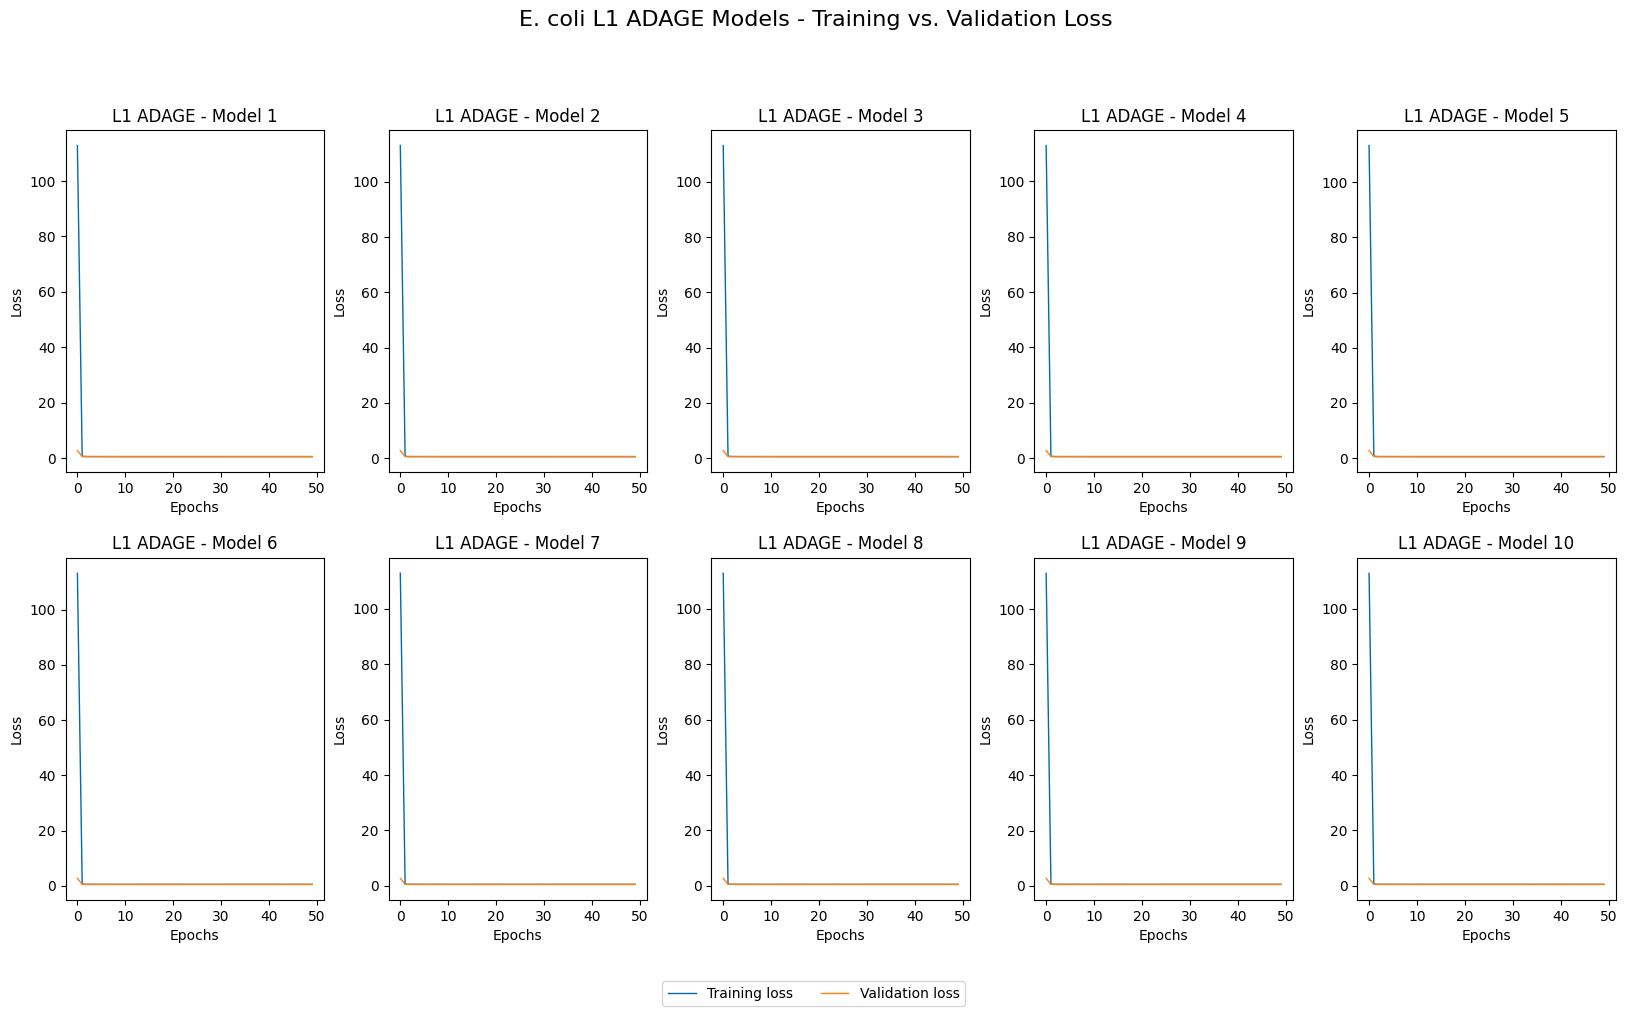

In [25]:
plot_titles = [
  f'L1 ADAGE - Model {i+1}'
  for i in range(10)
]
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli L1 ADAGE Models - Training vs. Validation Loss',
  fontsize = 16,
  y = 1
)

# Only plot curves for first 10 models - rest will be similar
for i in range(2):
  for j in range(5):
    ax[i, j].plot(
      range(50),
      loaded_models[5*i + j].history.history['loss'],
      linewidth = 1,
      label = 'Training loss'
    )
    ax[i, j].plot(
      range(50),
      loaded_models[5*i + j].history.history['val_loss'],
      linewidth = 1,
      label = 'Validation loss'
    )
    ax[i, j].set(
      title = plot_titles[5*i + j],
      xlabel = 'Epochs',
      ylabel = 'Loss'
    )

handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(
  handles,
  labels,
  loc = 'lower center',
  ncol = 2,
  fontsize = 10
)

fig.savefig(
  '/content/drive/MyDrive/Mukundan - Senior Project/L1 Models/Plots/ec_l1_loss.png',
  dpi = 300,
  bbox_inches = 'tight'
)

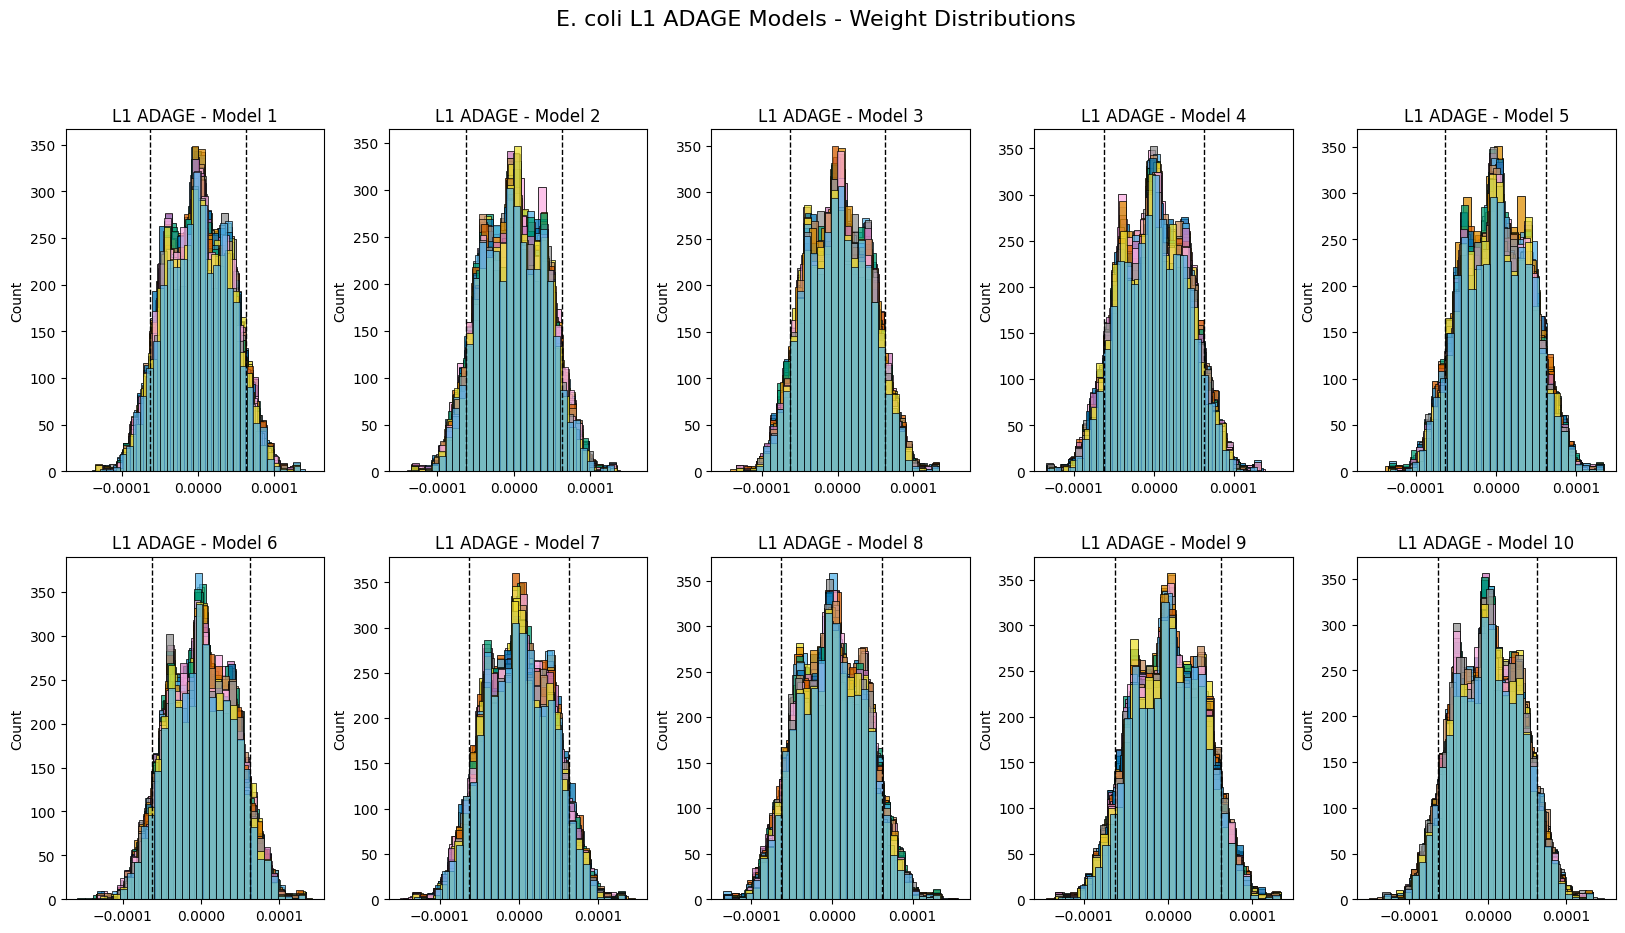

In [28]:
plot_titles = [
  f'L1 ADAGE - Model {i+1}'
  for i in range(10)
]
fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli L1 ADAGE Models - Weight Distributions',
  fontsize = 16,
  y = 1
)
colorblind_colors = sns.color_palette("colorblind")

for i in range(2):
  for j in range(5):
    weights_matrix = np.asarray(loaded_models[5*i + j].autoencoder.get_weights()[0])

    for node in range(optimal_hps['units']):
      weights = weights_matrix[:, node]
      weights = weights[np.isfinite(weights)]

      # Skip empty arrays or constant distributions
      if len(weights) == 0 or np.min(weights) == np.max(weights):
        continue

      # Each hidden node weight distribution
      sns.histplot(
        weights,
        ax = ax[i, j],
        color = colorblind_colors[node % len(colorblind_colors)],
        bins = 30,
        kde = False
      )

    all_weights = weights_matrix.flatten()
    all_weights = all_weights[np.isfinite(all_weights)]
    cutoff = np.std(all_weights) * 1.5

    ax[i, j].axvline(
        x = cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].axvline(
        x = -cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].set(title = plot_titles[5*i + j])

fig.savefig(
  '/content/drive/MyDrive/Mukundan - Senior Project/L1 Models/Plots/ec_l1_weight_dists.png',
  dpi = 300,
  bbox_inches = 'tight'
)

### 2e. Perform KEGG analysis

In [29]:
# Load KEGG p-value matrices
kegg_ps = [
  pd.read_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/kegg_dfs/ec_L1_kegg_ps{i+1}.csv'
  )
  for i in range(75)
]

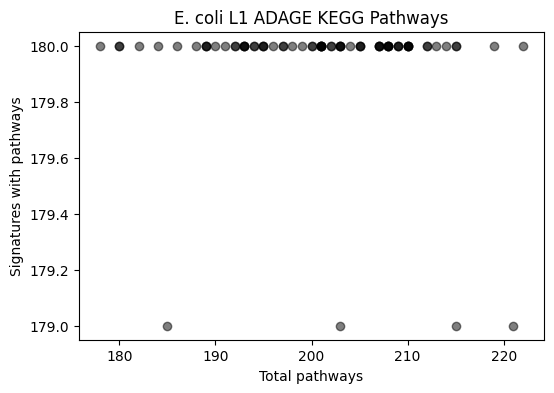

In [30]:
# Plot KEGG pathways
plt.figure(figsize = (6, 4))

for kegg_vals in kegg_ps:
  x = ((kegg_vals > 1.5).sum(0) > 0).sum()
  y = ((kegg_vals > 1.5).sum(1) > 0).sum()
  plt.scatter(x, y, alpha = 0.5, color = "black")

plt.title('E. coli L1 ADAGE KEGG Pathways')
plt.xlabel('Total pathways')
plt.ylabel('Signatures with pathways')

plt.savefig(
  '/content/drive/MyDrive/Mukundan - Senior Project/L1 Models/Plots/ec_l1_kegg.png',
  dpi = 300,
  bbox_inches = 'tight'
)